In [36]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
from tqdm import tqdm

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik, chi_squared
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
dataset, variances = load_data_and_var()

In [128]:
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset, variances)

In [129]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

In [130]:
test_nfw = nfws[5]

In [6]:
test_nfw.M500.value

354288799999999.94

In [7]:
test_nfw.M500.plus

33280699999999.996

In [215]:
print(test_nfw.heating.get_Linj_from_L500(1e44))

3.16227766016838e+44 ± 8.009554740232983e+43


In [218]:
from cluster_error_prop import Linj_from_L500
Linj_from_L500(0)

3.16227766016838e+44

In [8]:
s0 = 1e-27
mx=1e-2

In [246]:
def estimate_uncertainty_monte_carlo(nfw, mx, s0, num_samples=100):
    # Means and standard deviations for the parameters
    mLinj_mean = 0.38
    mLinj_std = 0.03
    bLinj_mean = 10.0
    bLinj_std = 0.11
    mT500_mean = 4.71
    mT500_std = 0.26
    bT500_mean = -2.34
    bT500_std = 0.09
    
    M500_mean = nfw.M500.value
    M500_std = max(nfw.M500.plus, nfw.M500.minus)
    
    sampled_params={
        'M500': [],
        'mLinj': [],
        'bLinj': [],
        'mT500': [],
        'bT500': []
    }

    L500_samples = []
    for _ in tqdm(range(num_samples), desc="Monte Carlo Simulation"):#range(num_samples):
        #mLinj_sample = np.random.normal(mLinj_mean, mLinj_std)
        #bLinj_sample = np.random.normal(bLinj_mean, bLinj_std)
        #mT500_sample = np.random.normal(mT500_mean, mT500_std)
        #bT500_sample = np.random.normal(bT500_mean, bT500_std)
        M500_sample = np.random.normal(M500_mean, M500_std)
        
        scaling_params={
                'mLinj': np.random.normal(mLinj_mean, mLinj_std),
                'bLinj': np.random.normal(bLinj_mean, bLinj_std),
                'mT500': np.random.normal(mT500_mean, mT500_std),
                'bT500': np.random.normal(bT500_mean, bT500_std)
        }
            
        #print(scaling_params)
        #print(M500_sample)

        L500_sample = nfw.precalc.L500_numerical_sampled(M500_sample, mx, s0, scaling_params)
        L500_samples.append(L500_sample)
        
        sampled_params['M500'].append(M500_sample)
        sampled_params['mLinj'].append(scaling_params['mLinj'])
        sampled_params['bLinj'].append(scaling_params['bLinj'])
        sampled_params['mT500'].append(scaling_params['mT500'])
        sampled_params['bT500'].append(scaling_params['bT500'])
        

    L500_samples = np.array(L500_samples)
    uncertainty = np.std(L500_samples)
    return uncertainty, L500_samples, sampled_params

In [248]:
unc_27_2, samples, params_dict = estimate_uncertainty_monte_carlo(test_nfw, mx, s0)

Monte Carlo Simulation:   2%|▍                  | 2/100 [00:00<00:10,  8.95it/s]

L -2.0 heating 1.3578562743077381e+44 cooling 6.152361558534751e+44 dm cooling 1.0312345249796263e+43
L 3.0 heating 6.429437712851139e+45 cooling 2.0370568355080147e+45 dm cooling 2.7741492583226193e+44
L -1.468195748038436 heating 2.0466433896838087e+44 cooling 6.98787898892198e+44 dm cooling 1.426851079431575e+43
L 0.7659021259807821 heating 1.1471166546777431e+45 cooling 1.1930928991527073e+45 dm cooling 6.012028156086694e+43
L 1.296481964692839 heating 1.7273713109042462e+45 cooling 1.3547228532275662e+45 dm cooling 8.589186209140437e+43
L 0.909194044954747 heating 1.2812076570674653e+45 cooling 1.2347399823487982e+45 dm cooling 6.616885336773151e+43
L 0.9397690350823104 heating 1.3117893451475778e+45 cooling 1.2438129484900309e+45 dm cooling 6.753947086587456e+43
L 0.9391056657067978 heating 1.3111181456322895e+45 cooling 1.2436153913628632e+45 dm cooling 6.7509422286525e+43
L 0.9391156373480859 heating 1.3111282324319033e+45 cooling 1.2436183607714083e+45 dm cooling 6.75098738681

Monte Carlo Simulation:   4%|▊                  | 4/100 [00:00<00:10,  8.96it/s]

L -2.0 heating 9.8156998149821e+43 cooling 7.42218630853139e+44 dm cooling 1.2287862260441022e+43
L 3.0 heating 6.218188381485722e+45 cooling 2.4406795865756695e+45 dm cooling 3.1366016726220764e+44
L -1.2034976529869765 heating 1.9008143906388455e+44 cooling 8.971949817652739e+44 dm cooling 1.9847111204463051e+43
L 0.898251173506512 heating 1.0871808478459914e+45 cooling 1.4797856186531204e+45 dm cooling 7.567029733461447e+43
L 1.949125586753256 heating 2.6000567910431764e+45 cooling 1.9004427252498084e+45 dm cooling 1.5283502931519318e+44
L 1.3830512302047677 heating 1.6255441769350052e+45 cooling 1.6608296288996535e+45 dm cooling 1.0441505439901794e+44
L 1.5472277179457483 heating 1.8627712708776398e+45 cooling 1.7270314269815566e+45 dm cooling 1.1655294054143285e+44
L 1.5274021168551606 heating 1.8323794191705343e+45 cooling 1.7188989923264568e+45 dm cooling 1.1501263598326185e+44
L 1.5288682494991077 heating 1.8346098629863094e+45 cooling 1.71949908446264e+45 dm cooling 1.15125818

Monte Carlo Simulation:   6%|█▏                 | 6/100 [00:00<00:10,  8.65it/s]

L -2.0 heating 5.831628172375592e+43 cooling 7.336193499136864e+44 dm cooling 1.2240724512241502e+43
L 3.0 heating 6.451903116199324e+45 cooling 2.3247145284689443e+45 dm cooling 2.820070197732416e+44
L -1.2415779271897418 heating 1.190740975470951e+44 cooling 8.738750236110672e+44 dm cooling 1.9056570703504505e+43
L 0.8792110364051289 heating 8.765013069144438e+44 cooling 1.4253104796691924e+45 dm cooling 7.040015261427691e+43
L 1.9396055182025644 heating 2.3780457340921893e+45 cooling 1.8202856862772974e+45 dm cooling 1.3980310245934949e+44
L 1.512288075480185 heating 1.590528840043127e+45 cooling 1.649418991503184e+45 dm cooling 1.0580721971177734e+44
L 1.6330767789634106 heating 1.7820402397007386e+45 cooling 1.6960223667348894e+45 dm cooling 1.1444548940307848e+44
L 1.6566701323559665 heating 1.8220571219838136e+45 cooling 1.7052778541198733e+45 dm cooling 1.1621639827191185e+44
L 1.6562120516882175 heating 1.8212716779705894e+45 cooling 1.70509767274707e+45 dm cooling 1.161817461

... (64 outputs left out)

Monte Carlo Simulation:  97%|█████████████████▍| 97/100 [00:10<00:00, 10.14it/s]

L -2.0 heating 1.1404598459279892e+44 cooling 7.1285025448845905e+44 dm cooling 1.2333843338917512e+43
L 3.0 heating 9.457944616041397e+45 cooling 2.293641394006991e+45 dm cooling 3.0223834965408997e+44
L -1.5911136667832038 heating 1.6367690778326603e+44 cooling 7.843366282224974e+44 dm cooling 1.5710218166183945e+43
L 0.7044431666083981 heating 1.2442054206356164e+45 cooling 1.3412631946516021e+45 dm cooling 6.567452987682176e+43
L 1.4307278320812142 heating 2.3637361776007507e+45 cooling 1.589409678180659e+45 dm cooling 1.0558867565064174e+44
L 0.8465889550887475 heating 1.4107159955474211e+45 cooling 1.386572486790826e+45 dm cooling 7.201877993165337e+43
L 0.9018805094623755 heating 1.481348892595308e+45 cooling 1.4046074645382324e+45 dm cooling 7.465633070454981e+43
L 0.8995729149221585 heating 1.4783315075864912e+45 cooling 1.4038501045144225e+45 dm cooling 7.454426397629094e+43
L 0.8996404476495384 heating 1.4784197252671484e+45 cooling 1.4038722631732185e+45 dm cooling 7.454754

Monte Carlo Simulation: 100%|█████████████████| 100/100 [00:10<00:00,  9.60it/s]

L -2.0 heating 7.068540322244161e+43 cooling 5.803053026273807e+44 dm cooling 9.611971045162909e+42
L 3.0 heating 6.454378473422285e+45 cooling 1.9992268456687146e+45 dm cooling 2.915537171990376e+44
L -1.445600315693401 heating 1.166037703435715e+44 cooling 6.656130910351347e+44 dm cooling 1.364921821718783e+43
L 0.7771998421532995 heating 8.675280198503256e+44 cooling 1.1535647187852085e+45 dm cooling 6.022449232059952e+43
L 1.8885999210766498 heating 2.3662954541672518e+45 cooling 1.5186301570862046e+45 dm cooling 1.314135865266481e+44
L 1.1393928231833745 heating 1.2030984492298611e+45 cooling 1.2617008039359942e+45 dm cooling 7.748893288004277e+43
L 1.336476702432603 heating 1.4374036031953242e+45 cooling 1.3247419525652138e+45 dm cooling 8.896509418404237e+43
L 1.3072491394879713 heating 1.399969123743378e+45 cooling 1.3151977228535405e+45 dm cooling 8.715796949562009e+43
L 1.3099234196598653 heating 1.4033534152690398e+45 cooling 1.3160681407022831e+45 dm cooling 8.7321731682645

In [249]:
unc_27_2

90.78879784165568

Text(0.5, 1.0, 'log(s0) = -27')

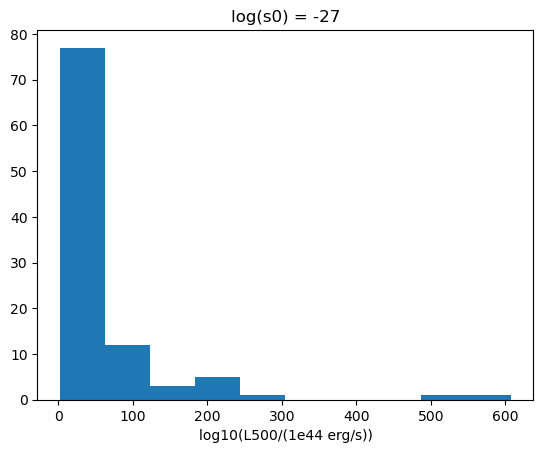

In [250]:
plt.hist(samples)
#plt.xlim(-5, 5)
plt.xlabel('log10(L500/(1e44 erg/s))')
plt.title('log(s0) = -27')

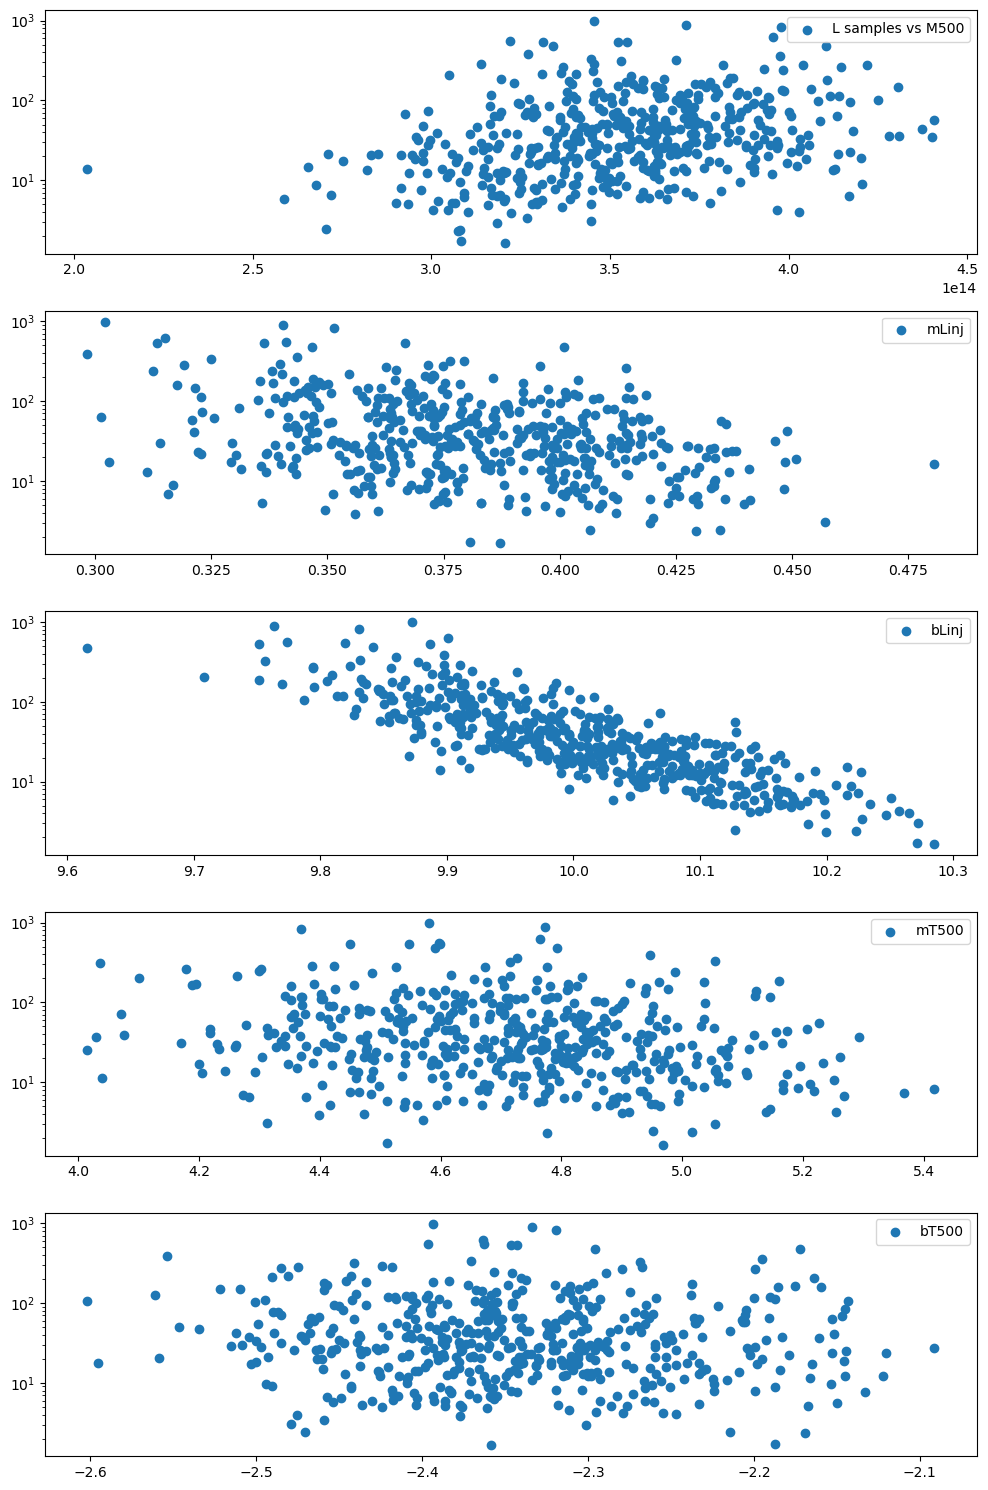

In [146]:

# Create a figure with 5 subplots arranged in a single column
fig, axs = plt.subplots(5, 1, figsize=(10, 15))

# Plot data on each subplot
axs[0].scatter(params_dict['M500'], samples, label='L samples vs M500')
#axs[0].set_title('sin(x)')
axs[0].legend()
axs[0].set_yscale('log')

axs[1].scatter(params_dict['mLinj'], samples, label='mLinj')
#axs[1].set_title('cos(x)')
axs[1].legend()
axs[1].set_yscale('log')

axs[2].scatter(params_dict['bLinj'], samples, label='bLinj')
#axs[2].set_title('tan(x)')
axs[2].legend()
axs[2].set_yscale('log')

axs[3].scatter(params_dict['mT500'], samples, label='mT500')
#axs[3].set_title('exp(x)')
axs[3].legend()
axs[3].set_yscale('log')

axs[4].scatter(params_dict['bT500'], samples, label='bT500')
#axs[4].set_title('log(x + 1)')
axs[4].legend()
axs[4].set_yscale('log')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()

In [147]:
unc_26_2, samples_26 = estimate_uncertainty_monte_carlo(test_nfw, mx, 1e-26)
unc_26_2

Monte Carlo Simulation:   2%|▎                  | 9/500 [00:00<00:42, 11.62it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.9540843141261327e+44, equation(30): -5.8790067374665086e+54
sigma0: 1e-26, mx: 0.01, scaling_params: {'mLinj': 0.32307341394122824, 'bLinj': 10.023871406036944, 'mT500': 4.352721662948853, 'bT500': -2.4041342331069204}, M500: 334464301971052.25


Monte Carlo Simulation:   5%|▉                 | 25/500 [00:02<00:40, 11.75it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.1685794235322155e+44, equation(30): -8.62923256510977e+53
sigma0: 1e-26, mx: 0.01, scaling_params: {'mLinj': 0.3036430350651293, 'bLinj': 9.949480427582278, 'mT500': 4.667996036882579, 'bT500': -2.270297116974793}, M500: 352298859568161.7


Monte Carlo Simulation:  11%|█▉                | 53/500 [00:04<00:37, 11.94it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.282141751987998e+44, equation(30): -1.8132523851045124e+55
sigma0: 1e-26, mx: 0.01, scaling_params: {'mLinj': 0.33421224319860554, 'bLinj': 10.124659056658121, 'mT500': 4.192806936506852, 'bT500': -2.3938611904002003}, M500: 380292798661556.0


... (3 outputs left out)

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.631950713810318e+44, equation(30): -1.275808945563274e+53
sigma0: 1e-26, mx: 0.01, scaling_params: {'mLinj': 0.30390935036946876, 'bLinj': 10.19894971869535, 'mT500': 4.777607019422136, 'bT500': -2.584431199562256}, M500: 372107064688627.2


Monte Carlo Simulation:  24%|████             | 120/500 [00:10<00:33, 11.46it/s]


Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.2469871053290357e+44, equation(30): -5.69206661240928e+54
sigma0: 1e-26, mx: 0.01, scaling_params: {'mLinj': 0.349824242552242, 'bLinj': 10.077501144228878, 'mT500': 4.206024062063135, 'bT500': -2.4146219550772563}, M500: 370298173668145.2
Error finding log_L_solution with root_scalar: root_scalar did not converge


ValueError: root_scalar did not converge

(array([  7.,   0.,   0.,   0.,   0.,   0.,  23.,  31., 905.,  34.]),
 array([-28.6654242 , -24.9122041 , -21.158984  , -17.4057639 ,
        -13.6525438 ,  -9.8993237 ,  -6.14610361,  -2.39288351,
          1.36033659,   5.11355669,   8.86677679]),
 <BarContainer object of 10 artists>)

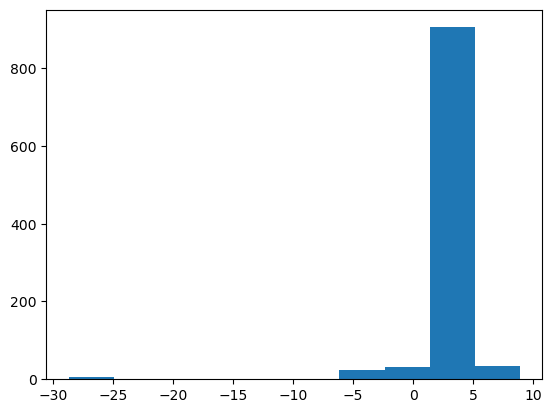

In [102]:
plt.hist(np.log10(samples_26))

In [236]:
unc_25_2, samples_25, params_dict_25 = estimate_uncertainty_monte_carlo(test_nfw, mx, 1e-25)
unc_25_2

Monte Carlo Simulation:   0%|                   | 2/500 [00:00<01:09,  7.17it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.228617078197691e+44, equation(10): -5.7155939036183017e+48
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.38436940987525564, 'bLinj': 9.889268020520632, 'mT500': 4.424419275771146, 'bT500': -2.3315404392485655}, M500: 319309910453986.25
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.44938288864423e+44, equation(10): -1.1398624185190303e+48
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.3741808882799133, 'bLinj': 10.192278694700766, 'mT500': 4.663297264450071, 'bT500': -2.3095489113528673}, M500: 324433347829703.2


Monte Carlo Simulation:   1%|▏                  | 4/500 [00:00<00:53,  9.21it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.183876199002411e+44, equation(10): -8.978321451892945e+47
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.3696829454285968, 'bLinj': 9.99612424687567, 'mT500': 4.96295227218862, 'bT500': -2.3188494222726117}, M500: 349252927056866.2
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.1453640537848416e+44, equation(10): -9.558829894856668e+48
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.39011532676367366, 'bLinj': 9.924868506114597, 'mT500': 4.308348517363865, 'bT500': -2.3007118467464074}, M500: 395234103752077.6


Monte Carlo Simulation:   2%|▎                  | 8/500 [00:00<00:46, 10.66it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.076925970248343e+44, equation(10): -1.4138830132093038e+49
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.41749447982890076, 'bLinj': 10.069895908921996, 'mT500': 4.021611568617862, 'bT500': -2.283216428970294}, M500: 345166393352278.94
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.386442148216667e+44, equation(10): -5.3365655383892214e+48
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.3626621065538414, 'bLinj': 10.05191376445093, 'mT500': 4.564655274317136, 'bT500': -2.392036848399159}, M500: 380413543618245.06


... (245 outputs left out)

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.114263379442434e+44, equation(10): -3.216068221256645e+48
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.3425673583822766, 'bLinj': 9.728307287528024, 'mT500': 4.836494005706638, 'bT500': -2.2950044654759774}, M500: 354458151813847.25
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.242783762825494e+44, equation(10): -2.7105052746531464e+48
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.36379670664537345, 'bLinj': 9.94873786912804, 'mT500': 4.691016257502259, 'bT500': -2.2901958367855415}, M500: 309151847472138.0


/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:253: RuntimeWarning: overflow encountered in power
/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:248: RuntimeWarning: overflow encountered in power
/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:209: RuntimeWarning: invalid value encountered in scalar subtract
  upper = 50
Monte Carlo Simulation:  77%|█████████████    | 383/500 [00:40<00:12,  9.53it/s]


Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -6.431188125983861e+44, equation(10): -1.1483887757303006e+48
sigma0: 1e-25, mx: 0.01, scaling_params: {'mLinj': 0.3914342273291278, 'bLinj': 9.983925271364964, 'mT500': 4.853079815672631, 'bT500': -2.369505573110328}, M500: 424179650805465.6
Error finding log_L_solution with root_scalar: root_scalar did not converge


ValueError: root_scalar did not converge

9560141179.442163

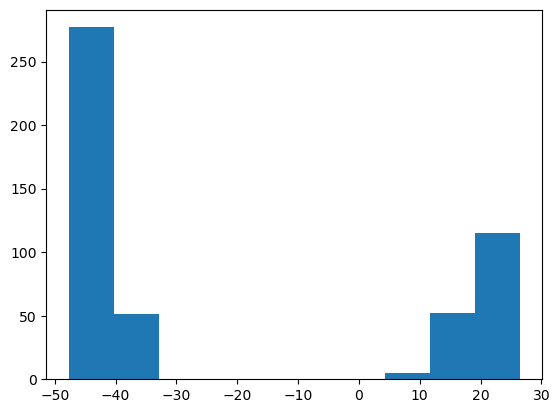

In [235]:
plt.hist(np.log(samples_25))
np.mean(samples_25)

In [232]:
test_nfw.L_err

0.30714760864929636

In [212]:
u.keV.to(u.GeV)

1e-06

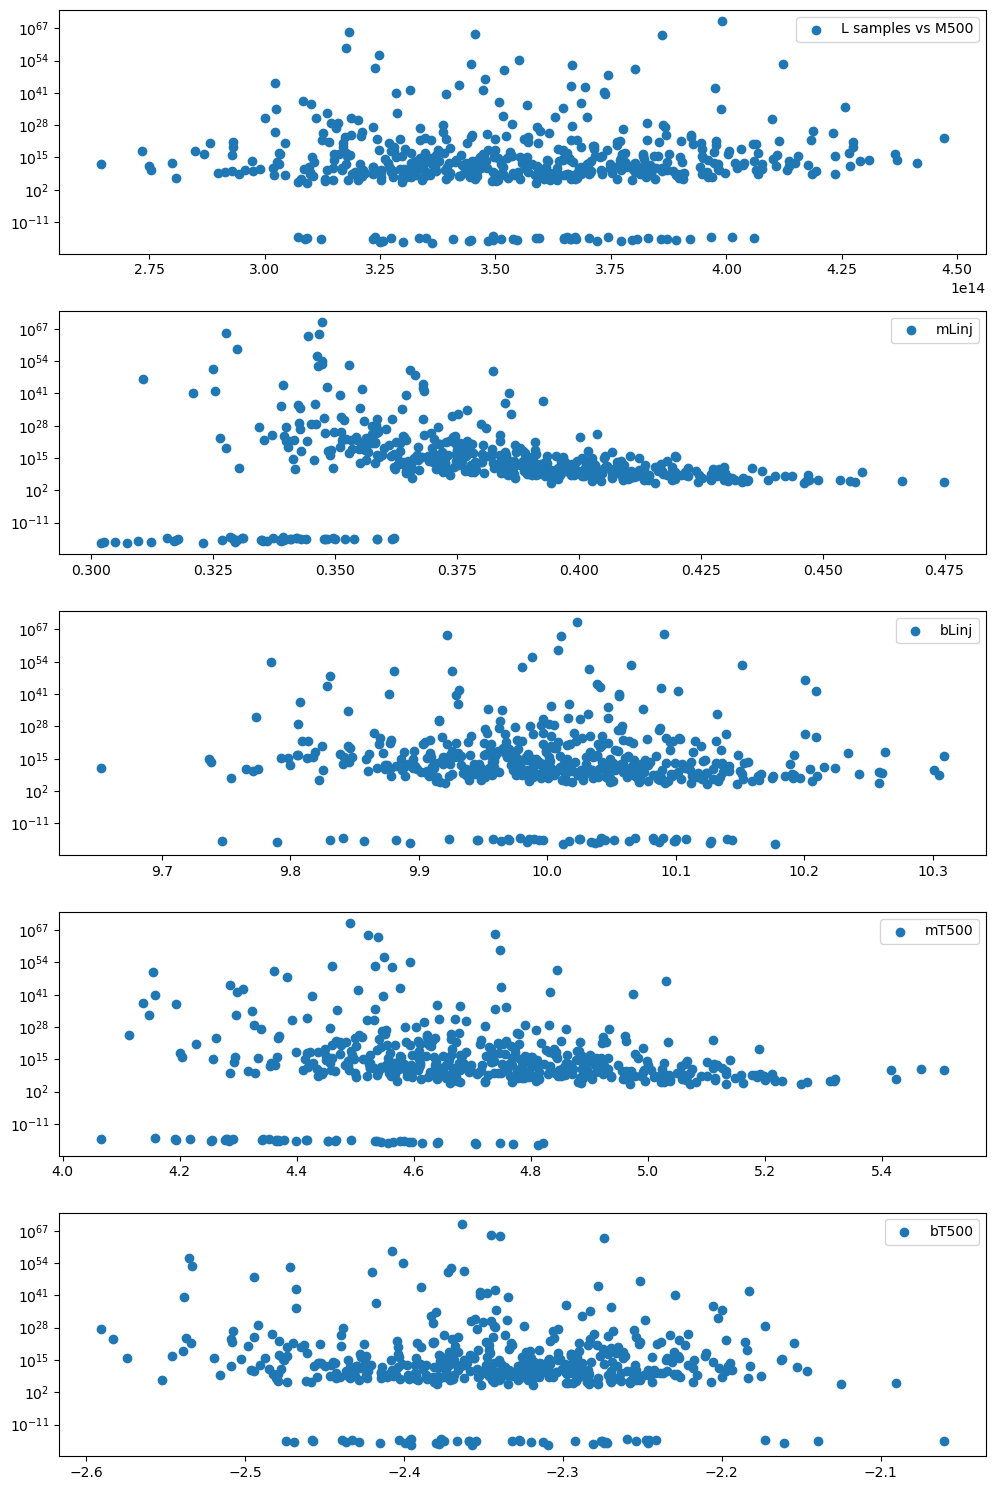

In [201]:

# Create a figure with 5 subplots arranged in a single column
fig, axs = plt.subplots(5, 1, figsize=(10, 15))

# Plot data on each subplot
axs[0].scatter(params_dict_25['M500'], samples_25, label='L samples vs M500')
#axs[0].set_title('sin(x)')
axs[0].legend()
axs[0].set_yscale('log')

axs[1].scatter(params_dict_25['mLinj'], samples_25, label='mLinj')
#axs[1].set_title('cos(x)')
axs[1].legend()
axs[1].set_yscale('log')

axs[2].scatter(params_dict_25['bLinj'], samples_25, label='bLinj')
#axs[2].set_title('tan(x)')
axs[2].legend()
axs[2].set_yscale('log')

axs[3].scatter(params_dict_25['mT500'], samples_25, label='mT500')
#axs[3].set_title('exp(x)')
axs[3].legend()
axs[3].set_yscale('log')

axs[4].scatter(params_dict_25['bT500'], samples_25, label='bT500')
#axs[4].set_title('log(x + 1)')
axs[4].legend()
axs[4].set_yscale('log')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()

In [ ]:
unc_24_2, samples_24 = estimate_uncertainty_monte_carlo(test_nfw, mx, 1e-24)
unc_24_2

In [ ]:
plt.plot([-27, -26, -25, -24], [unc_27_2, unc_26_2, unc_25_2, unc_24_2])
plt.yscale('log')
plt.xlabel('log(sigma0)')
plt.ylabel('uncertainty')

In [25]:
old_unc_27_2 = test_nfw.L500_numerical(1e-2, 1e-27)[1]
old_unc_27_2

370.0639133307998

In [26]:
old_unc_26_2 = test_nfw.L500_numerical(1e-2, 1e-26)[1]
old_unc_26_2

185026508.08418393

In [27]:
old_unc_25_2 = test_nfw.L500_numerical(1e-2, 1e-25)[1]
old_unc_25_2

1.578197657358715e+84

In [28]:
old_unc_24_2 = test_nfw.L500_numerical(1e-2, 1e-24)[1]
old_unc_24_2

3.8856684602391853e+161

Text(0, 0.5, 'variance (old method)')

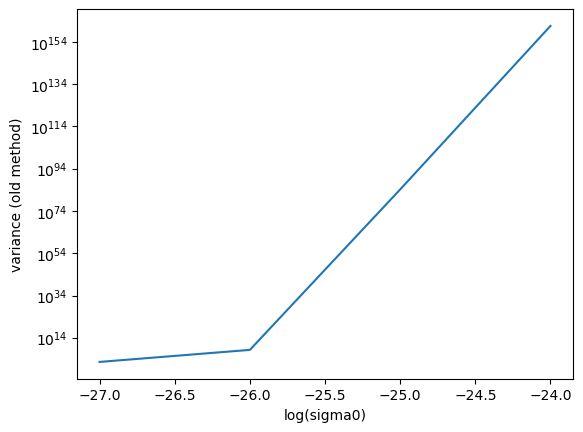

In [29]:
plt.plot([-27, -26, -25, -24], [old_unc_27_2, old_unc_26_2, old_unc_25_2, old_unc_24_2])
plt.yscale('log')
plt.xlabel('log(sigma0)')
plt.ylabel('variance (old method)')

In [40]:
test_nfw.L500.value, test_nfw.L_err

(2.164603, 0.30714760864929636)

In [42]:
test_nfw.L500_numerical(1e-2, 1e-28)

(26.842597492092583, 222.1046719882638)

In [41]:
test_nfw.L500_numerical(1e-2, 1e-27)

(33.507176490104904, 370.0639133307998)

In [45]:
model = test_nfw.L500_numerical(1e-2, 1e-27)[0]
add_var = test_nfw.L500_numerical(1e-2, 1e-27)[1]
X2 = chi_squared(model, test_nfw.L500, test_nfw.L_err, add_var)

In [46]:
log_lik = -X2/2

In [47]:
log_lik

In [48]:
model = test_nfw.L500_numerical(1e-2, 1e-27)[0]
add_var = unc_27_2
X2 = chi_squared(model, test_nfw.L500, test_nfw.L_err, add_var)

In [50]:
log_lik = -X2/2
log_lik

In [53]:
M500_values = [nfw.M500.value for nfw in nfws]
unique_M500_values = set(M500_values)

In [54]:
len(unique_M500_values)

111

In [59]:
nfws_subset = nfws[:10]
s0s = [1e-29, 1e-28, 1e-27, 1e-26, 10**-25.5, 1e-25, 10**-24.75, 10**-24.5, 10**-24.25, 1e-24]

In [64]:
mx=1e-2
def calculate_uncertainties(nfws, s0s, num_samples=1000):
    uncertainties = {}
    for nfw in nfws:
        M500_value = nfw.M500.value
        uncertainties[M500_value] = {}
        for s0 in s0s:
            uncertainty = estimate_uncertainty_monte_carlo(nfw, mx, s0, num_samples=num_samples)
            uncertainties[M500_value][s0] = uncertainty
    return variances

In [65]:
uncertainties = calculate_uncertainties(nfws_subset, s0s)
for M500_value, s0_dict in uncertainties.items():
    for s0, uncertainty in s0_dict.items():
        print(f"Variance for M500={M500_value} and s0={s0}: {uncertainty}")

Monte Carlo Simulation:  85%|█████████████▌  | 849/1000 [01:00<00:11, 13.64it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -1.6529307430666377e+44, equation(30): -3.1961380151957137e+53


Monte Carlo Simulation:   0%|                  | 4/1000 [00:00<01:08, 14.58it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -1.7485715863150401e+44, equation(30): -8.641659496198925e+55


Monte Carlo Simulation:   2%|▎                | 18/1000 [00:01<01:06, 14.84it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -1.9250901758463452e+44, equation(30): -4.332430413693293e+54


... (9 outputs left out)

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.2450445528160782e+44, equation(30): -6.755818667597632e+53


Monte Carlo Simulation:  40%|██████▍         | 400/1000 [00:27<00:40, 14.90it/s]/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:225: RuntimeWarning: overflow encountered in power
/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:220: RuntimeWarning: overflow encountered in power
/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:185: RuntimeWarning: invalid value encountered in scalar subtract
  return heating_rate - cooling_rate - dm_cooling_rate
/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:185: RuntimeWarning: invalid value encountered in subtract
  return heating_rate - cooling_rate - dm_cooling_rate
Monte Carlo Simulation:  40%|██████▍         | 400/1000 [00:27<00:40, 14.75it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -1.6210522420526581e+44, equation(30): -2.815267717194626e+53
Error finding log_L_solution with root_scalar: root_scalar did not converge
Unexpected exception formatting exception. Falling back to standard exception



Traceback (most recent call last):
  File "/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py", line 199, in L500_numerical_sampled
    log_L_solution = brentq(equation, lower, upper)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py", line 799, in brentq
    r = _zeros._brentq(f, a, b, xtol, rtol, maxiter, args, full_output, disp)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: f(a) and f(b) must have different signs

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3526, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_36941/2223770413.py", line 1, in <mod

In [69]:
L500_soln = [test_nfw.L500_numerical(1e-2, s)[0] for s in s0s]

In [74]:
L500_uncs = [estimate_variance_monte_carlo(test_nfw, 1e-2, s) for s in s0s[1:]]

Monte Carlo Simulation:   2%|▎                | 16/1000 [00:01<01:37, 10.11it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.0852701140122575e+44, equation(30): -2.0273983174634414e+54
sigma0: 1e-27, mx: 0.01, scaling_params: {'mLinj': 0.3144157049054923, 'bLinj': 9.930302542570963, 'mT500': 4.162397674744447, 'bT500': -2.46257719262048}, M500: 368624520082180.06


Monte Carlo Simulation:  82%|█████████████   | 818/1000 [01:21<00:17, 10.24it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.8798693839917046e+44, equation(30): -4.285330413291909e+54
sigma0: 1e-27, mx: 0.01, scaling_params: {'mLinj': 0.34543235302607656, 'bLinj': 10.123048729468625, 'mT500': 3.89391105767113, 'bT500': -2.340951052457674}, M500: 376168736596332.5


Monte Carlo Simulation:  90%|██████████████▍ | 902/1000 [01:29<00:10,  9.62it/s]/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py:315: RuntimeWarning: Derivative was zero.
  warnings.warn(msg, RuntimeWarning)
Monte Carlo Simulation:  90%|██████████████▍ | 903/1000 [01:29<00:09, 10.09it/s]


Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.8418047364363732e+44, equation(30): -6.490522932239363e+52
sigma0: 1e-27, mx: 0.01, scaling_params: {'mLinj': 0.3035880895865473, 'bLinj': 10.011824724362915, 'mT500': 4.39194958114727, 'bT500': -2.378080112801035}, M500: 341209174944764.8
Error finding log_L_solution with root_scalar: root_scalar did not converge
Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py", line 199, in L500_numerical_sampled
    log_L_solution = brentq(equation, lower, upper)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py", line 799, in brentq
    r = _zeros._brentq(f, a, b, xtol, rtol, maxiter, args, full_output, disp)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: f(a) and f(b) must have different signs

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3526, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_36941/2814252206.py", line 1, in <modu

Text(0, 0.5, 'L500 numerical solution (1e44 erg/s)')

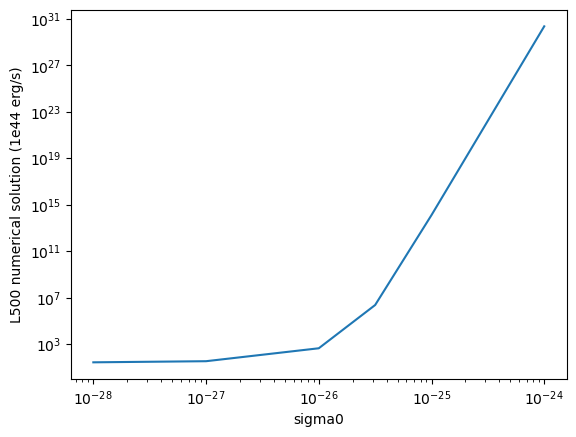

In [72]:
plt.loglog(s0s, L500_soln)
plt.loglog(s0s, L500_uncs)
plt.xlabel('sigma0')
plt.ylabel('L500 numerical solution (1e44 erg/s)')